In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import os
import pickle

In [2]:
file_path = r"C:\Users\Dell\Desktop\Analytics Platform\ecommerce_cleaned.csv"

df = pd.read_csv(file_path)

df["Order Date"] = pd.to_datetime(df["Order Date"])

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (2000, 13)


,Order ID,Customer ID,Product ID,Product Name,Product Category,Quantity,Price (INR),Discount (%),Order Date,Customer Location,Rating,Review,Sales/Revenue (INR)
0,ORD00091,CUST1105,P009,Sneakers,Clothing,5,2907.60,25,2023-09-23,Hyderabad,1,Very disappointing purchase,10903.50
1,ORD00210,CUST1064,P005,Laptop,Electronics,3,52234.91,15,2024-12-26,Chandigarh,2,Not very satisfied with the product,133199.02
2,ORD00105,CUST1006,P010,Kurta,Clothing,4,1000.22,20,2026-02-23,Gurugram,2,"Below average, needs improvement",3200.70
3,ORD00244,CUST1087,P008,Jacket,Clothing,5,2515.47,5,2023-12-16,Gurugram,2,Not very satisfied with the product,11948.48
4,ORD00014,CUST1119,P015,Table Lamp,Home & Kitchen,3,983.81,0,2021-03-30,Mumbai,5,"Amazing product, highly recommended",2951.43


In [3]:
# check the data

print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDate range:")
print(df["Order Date"].min())
print(df["Order Date"].max())

Columns:
['Order ID', 'Customer ID', 'Product ID', 'Product Name', 'Product Category', 'Quantity', 'Price (INR)', 'Discount (%)', 'Order Date', 'Customer Location', 'Rating', 'Review', 'Sales/Revenue (INR)']

Missing values:
Order ID               0
Customer ID            0
Product ID             0
Product Name           0
Product Category       0
Quantity               0
Price (INR)            0
Discount (%)           0
Order Date             0
Customer Location      0
Rating                 0
Review                 0
Sales/Revenue (INR)    0
dtype: int64

Date range:
2020-01-01 00:00:00
2026-09-15 00:00:00


In [4]:
# Create daily sales data

daily_sales = (
    df.groupby("Order Date")["Sales/Revenue (INR)"]
    .sum()
    .reset_index()
)

daily_sales.columns = ["Date", "Revenue"]

daily_sales = daily_sales.sort_values("Date")

print("Daily sales dataset:")
print(daily_sales.head())

print("\nShape:", daily_sales.shape)

Daily sales dataset:
        Date  Revenue
0 2020-01-01  7287.53
1 2020-01-02  6296.39
2 2020-01-05   180.17
3 2020-01-06  1653.34
4 2020-01-07  1755.22

Shape: (1402, 2)


In [5]:
# Create time-based features

daily_sales["Day"] = daily_sales["Date"].dt.day
daily_sales["Month"] = daily_sales["Date"].dt.month
daily_sales["Year"] = daily_sales["Date"].dt.year
daily_sales["DayOfWeek"] = daily_sales["Date"].dt.dayofweek
daily_sales["DayOfYear"] = daily_sales["Date"].dt.dayofyear

daily_sales.head()

,Date,Revenue,Day,Month,Year,DayOfWeek,DayOfYear
0,2020-01-01,7287.53,1,1,2020,2,1
1,2020-01-02,6296.39,2,1,2020,3,2
2,2020-01-05,180.17,5,1,2020,6,5
3,2020-01-06,1653.34,6,1,2020,0,6
4,2020-01-07,1755.22,7,1,2020,1,7


In [6]:
# Add previous sales feature

daily_sales["Previous_Day_Revenue"] = (
    daily_sales["Revenue"].shift(1)
)

daily_sales["Previous_7_Days_Revenue"] = (
    daily_sales["Revenue"].shift(7)
)

daily_sales["Previous_30_Days_Revenue"] = (
    daily_sales["Revenue"].shift(30)
)

daily_sales.head(10)

,Date,Revenue,Day,Month,Year,DayOfWeek,DayOfYear,Previous_Day_Revenue,Previous_7_Days_Revenue,Previous_30_Days_Revenue
0,2020-01-01,7287.53,1,1,2020,2,1,NaN,NaN,NaN
1,2020-01-02,6296.39,2,1,2020,3,2,7287.53,NaN,NaN
2,2020-01-05,180.17,5,1,2020,6,5,6296.39,NaN,NaN
3,2020-01-06,1653.34,6,1,2020,0,6,180.17,NaN,NaN
4,2020-01-07,1755.22,7,1,2020,1,7,1653.34,NaN,NaN
5,2020-01-11,656.18,11,1,2020,5,11,1755.22,NaN,NaN
6,2020-01-12,2590.54,12,1,2020,6,12,656.18,NaN,NaN
7,2020-01-13,12614.44,13,1,2020,0,13,2590.54,7287.53,NaN
8,2020-01-16,2940.15,16,1,2020,3,16,12614.44,6296.39,NaN
9,2020-01-17,67736.79,17,1,2020,4,17,2940.15,180.17,NaN


In [7]:
# remove missing values

daily_sales = daily_sales.dropna()

daily_sales = daily_sales.reset_index(drop=True)

print("Shape after removing missing values:")
print(daily_sales.shape)

daily_sales.head()

Shape after removing missing values:
(1372, 10)


,Date,Revenue,Day,Month,Year,DayOfWeek,DayOfYear,Previous_Day_Revenue,Previous_7_Days_Revenue,Previous_30_Days_Revenue
0,2020-02-26,3634.37,26,2,2020,2,57,6584.90,4120.63,7287.53
1,2020-02-27,1829.11,27,2,2020,3,58,3634.37,14974.23,6296.39
2,2020-02-29,3966.66,29,2,2020,5,60,1829.11,6611.88,180.17
3,2020-03-01,5011.61,1,3,2020,6,61,3966.66,13780.96,1653.34
4,2020-03-02,0.00,2,3,2020,0,62,5011.61,3987.30,1755.22


In [8]:
# Create x and y

features = [
    "Day",
    "Month",
    "Year",
    "DayOfWeek",
    "DayOfYear",
    "Previous_Day_Revenue",
    "Previous_7_Days_Revenue",
    "Previous_30_Days_Revenue"
]

X = daily_sales[features]

y = daily_sales["Revenue"]

print("Input features:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)


Input features:
['Day', 'Month', 'Year', 'DayOfWeek', 'DayOfYear', 'Previous_Day_Revenue', 'Previous_7_Days_Revenue', 'Previous_30_Days_Revenue']

X shape: (1372, 8)
y shape: (1372,)


In [9]:
# Splite into traning and testing data

split_index = int(len(daily_sales) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1097
Testing records: 275


In [10]:
# Train leaner regression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [11]:
# Train random forest

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [12]:
# Evaluate both models

def evaluate_model(model_name, y_test, predictions):

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }


linear_results = evaluate_model(
    "Linear Regression",
    y_test,
    linear_predictions
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions
)

results = pd.DataFrame([
    linear_results,
    rf_results
])

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,17324.020940,39192.181388,-0.009806
1,Random Forest,22263.895049,40683.810431,-0.088134


In [13]:
# Compare actual vs predicated sales

comparison = pd.DataFrame({
    "Date": daily_sales.loc[X_test.index, "Date"],
    "Actual Revenue": y_test.values,
    "Linear Prediction": linear_predictions,
    "Random Forest Prediction": rf_predictions
})

comparison.head(10)

,Date,Actual Revenue,Linear Prediction,Random Forest Prediction
1097,2025-05-15,1323.47,13010.379710,14668.50055
1098,2025-05-17,6611.60,13056.080722,11326.80295
1099,2025-05-19,3917.48,13557.812495,20170.10015
1100,2025-05-20,34939.91,13494.502982,16614.05685
1101,2025-05-21,9032.76,8850.349532,36566.27725
1102,2025-05-22,5979.90,11783.064936,26433.52685
1103,2025-05-23,0.00,13548.750504,13754.97430
1104,2025-05-24,11814.60,13016.897033,11509.36010
1105,2025-05-25,2737.66,12604.059872,12675.76255
1106,2025-05-26,3765.14,13710.087138,27276.85370


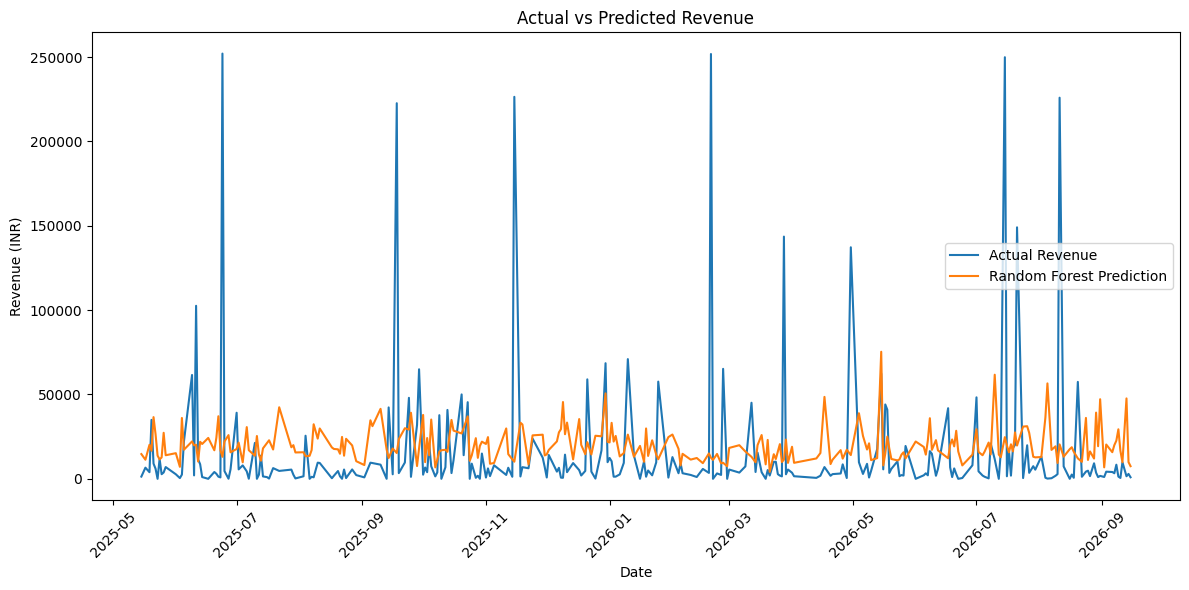

In [14]:
# Plot actual vs predicted revenue

plt.figure(figsize=(12, 6))

plt.plot(
    comparison["Date"],
    comparison["Actual Revenue"],
    label="Actual Revenue"
)

plt.plot(
    comparison["Date"],
    comparison["Random Forest Prediction"],
    label="Random Forest Prediction"
)

plt.title("Actual vs Predicted Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

In [15]:
# Select the best model

best_model_name = results.loc[
    results["RMSE"].idxmin(),
    "Model"
]

print("Best Model:", best_model_name)

Best Model: Linear Regression


In [16]:
# Save the best model

os.makedirs(r"C:\Users\Dell\Desktop\Analytics Platform", exist_ok=True)

if best_model_name == "Linear Regression":
    best_model = linear_model
else:
    best_model = rf_model

model_data = {
    "model": best_model,
    "features": features,
    "model_name": best_model_name
}

model_path = r"C:\Users\Dell\Desktop\Analytics Platform\sales_prediction_model.pkl"

with open(model_path, "wb") as file:
    pickle.dump(model_data, file)

print("Best sales prediction model saved successfully!")
print(model_path)

Best sales prediction model saved successfully!
C:\Users\Dell\Desktop\Analytics Platform\sales_prediction_model.pkl


In [17]:
# Save the evalution results

os.makedirs(r"C:\Users\Dell\Desktop\Analytics Platform", exist_ok=True)

results.to_csv(
    r"C:\Users\Dell\Desktop\Analytics Platform\sales_prediction_results.csv",
    index=False
)

comparison.to_csv(
    r"C:\Users\Dell\Desktop\Analytics Platform\sales_prediction_comparison.csv",
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [18]:
# Verify files

print(
    "Model exists:",
    os.path.exists(r"C:\Users\Dell\Desktop\Analytics Platform\sales_prediction_model.pkl")
)

print(
    "Results exist:",
    os.path.exists(r"C:\Users\Dell\Desktop\Analytics Platform\sales_prediction_results.csv")
)

print(
    "Comparison exists:",
    os.path.exists(r"C:\Users\Dell\Desktop\Analytics Platform\sales_prediction_comparison.csv")
)

Model exists: True
Results exist: True
Comparison exists: True
